In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
data=pd.read_csv("improved_disease_dataset.csv")

In [4]:
print(data)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes                       disease  
0         1            1     

In [5]:
from sklearn.preprocessing import LabelEncoder

In [6]:
encode=LabelEncoder()
data["disease"]=encode.fit_transform(data["disease"])
print(data)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes  disease  
0         1            1            0       29  
1

In [7]:
X=data.iloc[:,:-1]
Y=data.iloc[:,-1]

In [8]:
print(X)
print(Y)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes  
0         1            1            0  
1         1        

In [9]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

In [10]:
print("Before",Counter(Y))

Before Counter({29: 90, 20: 80, 16: 80, 24: 80, 7: 70, 17: 70, 34: 70, 10: 70, 37: 70, 6: 70, 33: 70, 21: 70, 26: 60, 13: 60, 28: 60, 14: 60, 8: 50, 31: 50, 35: 50, 22: 50, 5: 50, 4: 50, 18: 40, 23: 40, 1: 40, 12: 40, 30: 40, 32: 40, 11: 40, 9: 40, 36: 40, 15: 40, 19: 40, 27: 30, 3: 30, 25: 30, 0: 30, 2: 10})


In [11]:
print(Y)

0       29
1       29
2       29
3       29
4       29
        ..
1995     2
1996     2
1997     2
1998     2
1999     2
Name: disease, Length: 2000, dtype: int64


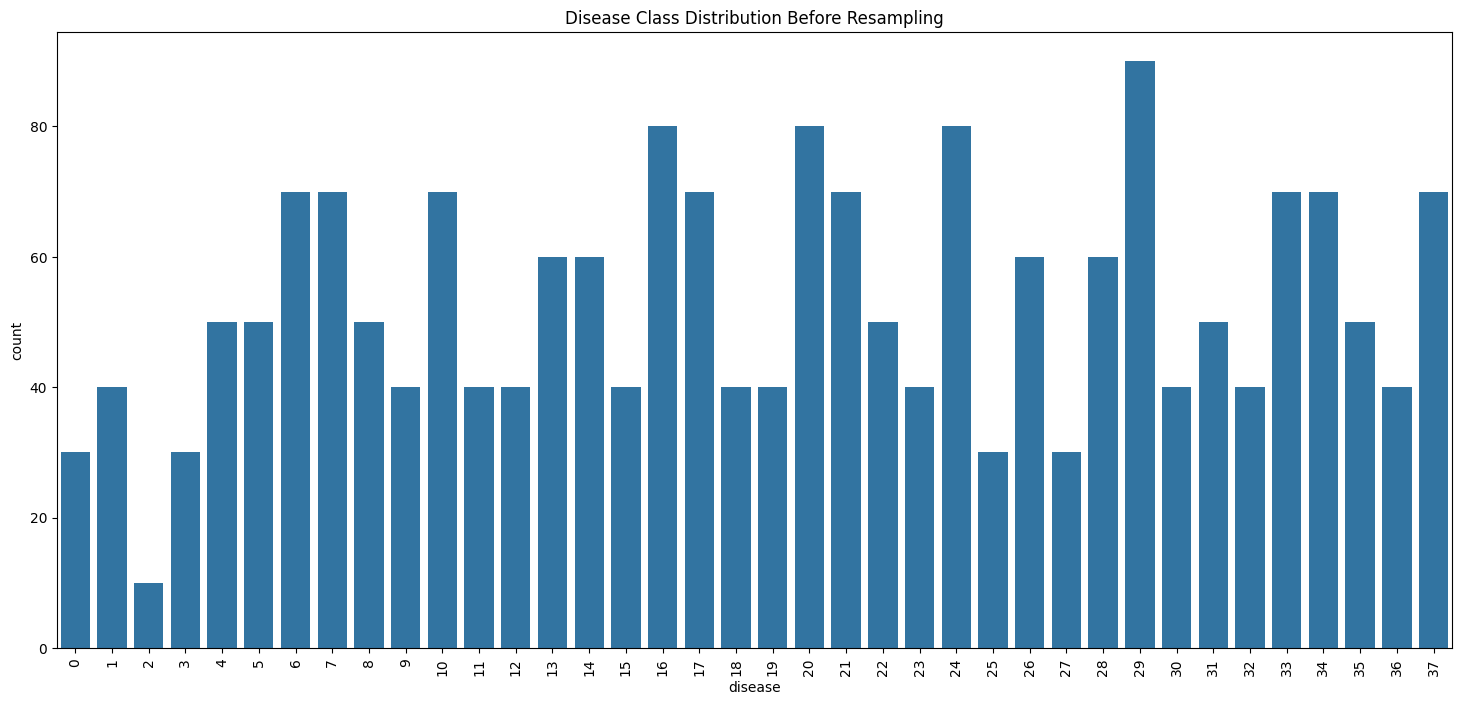

In [12]:


encoder = LabelEncoder()
data["disease"] = encoder.fit_transform(data["disease"])

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

plt.figure(figsize=(18, 8))
sns.countplot(x=y)
plt.title("Disease Class Distribution Before Resampling")
plt.xticks(rotation=90)
plt.show()

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)

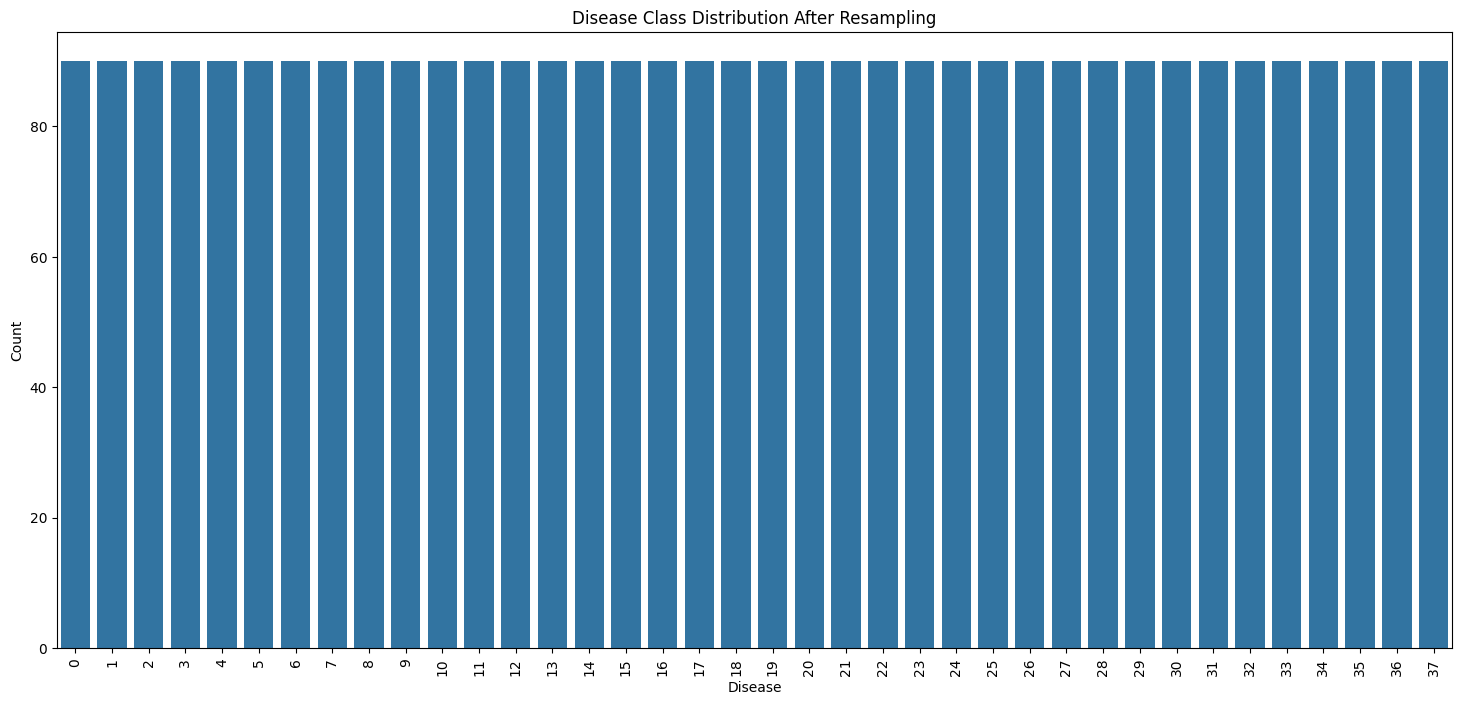

In [13]:
plt.figure(figsize=(18, 8))

sns.countplot(x=y_resampled)

plt.title("Disease Class Distribution After Resampling")
plt.xlabel("Disease")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

In [14]:
X_resampled=X_resampled.fillna(0)

In [15]:
print(X_resampled)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
3415      0         0       1         1        0           0          0   
3416      0         0       0         1        0           1          0   
3417      0         0       0         1        0           1          0   
3418      0         0       0         0        0           1          1   
3419      0         1       0         1        1           0          1   

      cough  weight_loss  yellow_eyes  
0         1            1            0  
1         1        

In [16]:
if len(y_resampled.shape)>1:
    y_resampled=y_resampled.values.ravel()

In [17]:
print(y_resampled)

0       29
1       29
2       29
3       29
4       29
        ..
3415    37
3416    37
3417    37
3418    37
3419    37
Name: disease, Length: 3420, dtype: int64


In [18]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [19]:
from sklearn.metrics import accuracy_score,confusion_matrix

In [20]:
from sklearn.model_selection import train_test_split,cross_val_score,StratifiedKFold

In [21]:
models={"DecisionTree":DecisionTreeClassifier(),
      "RandomForestClassifier":RandomForestClassifier(),
      "SVM":SVC()
}

In [22]:
cv_scoring="accurracy"
StratifiedKFold_kfold=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Evaluation metric
cv_scoring = 'accuracy'

# Stratified K-Fold
stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model evaluation
for model_name, model in models.items():
    try:
        scores = cross_val_score(
            model,
            X_resampled,
            y_resampled,
            cv=stratified_kfold,
            scoring=cv_scoring,
            n_jobs=-1,
            error_score='raise'
        )

        print("=" * 50)
        print(f"Model: {model_name}")
        print(f"Scores: {scores}")
        print(f"Mean Accuracy: {scores.mean():.4f}")

    except Exception as e:
        print("=" * 50)
        print(f"Model: {model_name} failed with error:")
        print(e)

Model: DecisionTree
Scores: [0.5497076  0.54385965 0.53508772 0.53654971 0.52631579]
Mean Accuracy: 0.5383
Model: RandomForestClassifier
Scores: [0.55116959 0.54532164 0.53654971 0.52631579 0.5380117 ]
Mean Accuracy: 0.5395
Model: SVM
Scores: [0.51315789 0.51169591 0.49707602 0.48245614 0.49561404]
Mean Accuracy: 0.5000


In [25]:
svm_model=SVC()
svm_model.fit(X_resampled,y_resampled)
svm_pred=svm_model.predict(X_resampled)
print(svm_pred)

[29 10 29 ... 37 24 27]


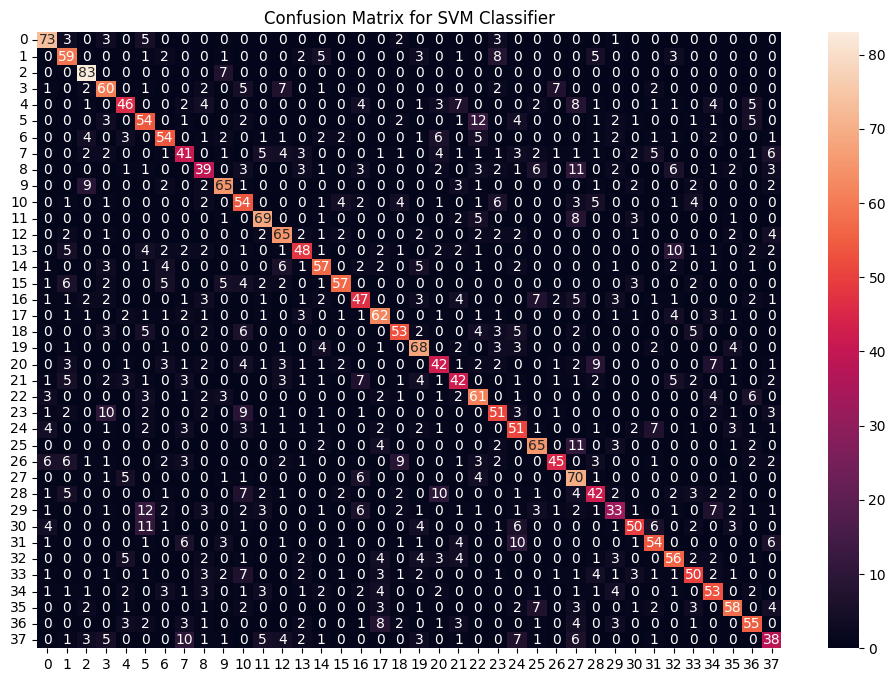

In [28]:
cf_matrix=confusion_matrix(y_resampled,svm_pred)
plt.figure(figsize=(12,8))
sns.heatmap(cf_matrix,annot=True,fmt="d")
plt.title("Confusion Matrix for SVM Classifier")
plt.show()

In [29]:
temp=accuracy_score(y_resampled,svm_pred)
print(temp)

0.6052631578947368


In [32]:
print(f"SVM Accuracy: {accuracy_score(y_resampled, svm_pred) * 100:.2f}%")

SVM Accuracy: 60.53%


In [33]:
from sklearn.naive_bayes import GaussianNB

In [35]:
gaussian_model=GaussianNB()
gaussian_model.fit(X_resampled,y_resampled)
gaussian_pred=gaussian_model.predict(X_resampled)
print(gaussian_pred)


[29 29 29 ...  2 24  2]


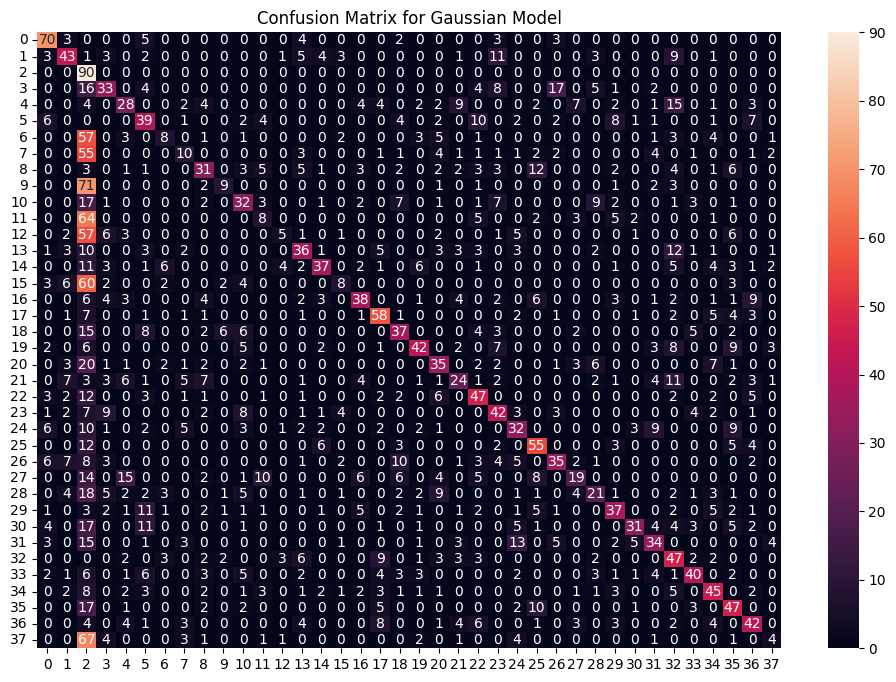

In [37]:
cf_matrix_gaussian=confusion_matrix(y_resampled,gaussian_pred)
plt.figure(figsize=(12,8))
sns.heatmap(cf_matrix_gaussian,annot=True,fmt="d")
plt.title("Confusion Matrix for Gaussian Model")
plt.show()

In [38]:
gaussian_accurracyy=accuracy_score(y_resampled,gaussian_pred)

In [40]:
print(gaussian_accurracyy)

0.3798245614035088


In [42]:
print(f"gaussian_accurracyy:{gaussian_accurracyy*100:.2f}%")

gaussian_accurracyy:37.98%


In [44]:
random_model=RandomForestClassifier(random_state=(42))
random_model.fit(X_resampled,y_resampled)
random_pred=random_model.predict(X_resampled)
print(random_pred)

[29 10 29 ... 37 24 37]


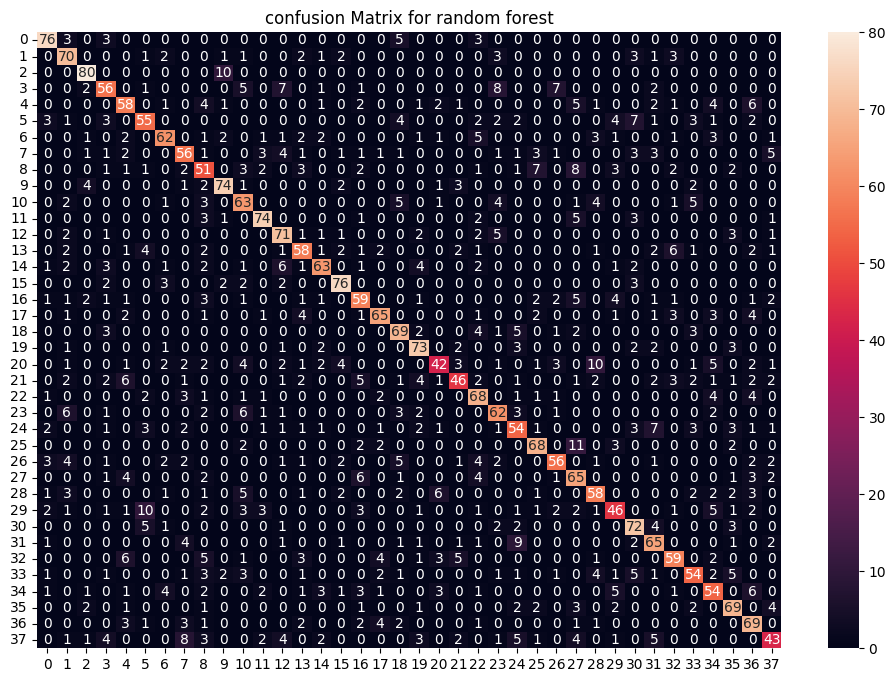

In [47]:
cf_matrix_random=confusion_matrix(y_resampled,random_pred)
plt.figure(figsize=(12,8))
sns.heatmap(cf_matrix_random,annot=True,fmt="d")
plt.title("confusion Matrix for random forest")
plt.show()


In [48]:
random_accuraccy=accuracy_score(y_resampled,random_pred)
print(f"Random forest accurracy:{random_accuraccy*100:.2f}%")

Random forest accurracy:68.98%
